Shape: (1000, 38)
Missing values: 0
Duplicate rows: 0

Stockout_Risk (%):
 Stockout_Risk
Low       66.8
High      25.2
Medium     8.0
Name: proportion, dtype: float64

On_Time_Delivery (%):
 On_Time_Delivery
No     72.2
Yes    27.8
Name: proportion, dtype: float64

=== Selected Descriptive Statistics ===
                                     Mean     Std. Dev.            Min       Median           Max
Current_Inventory                1,040.16        586.32          20.00     1,076.00      1,999.00
Reorder_Point                      487.82        227.55         100.00       489.50        899.00
Actual_Demand                      707.01        386.05          20.00       704.00      1,397.00
Lead_Time_Days                      22.76         12.49           1.00        22.50         44.00
Supplier_Reliability_Score          80.00         11.19          60.00        80.04         99.94
Unit_Cost_INR                   25,237.24     14,394.97          62.03    25,240.66     49,975.28
Selling_

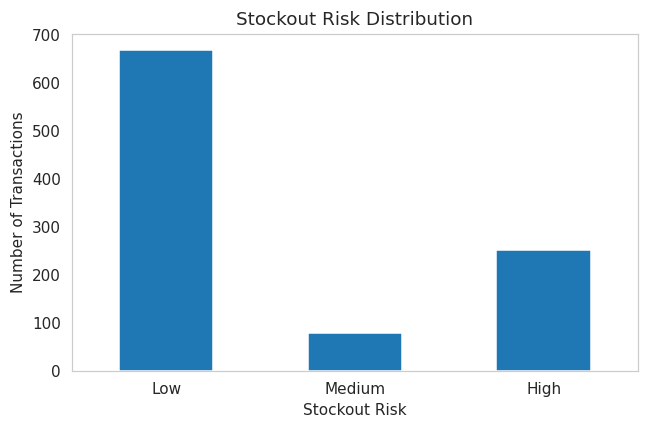

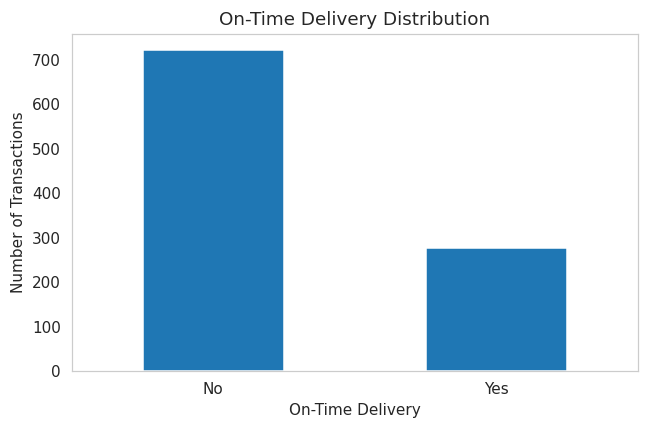

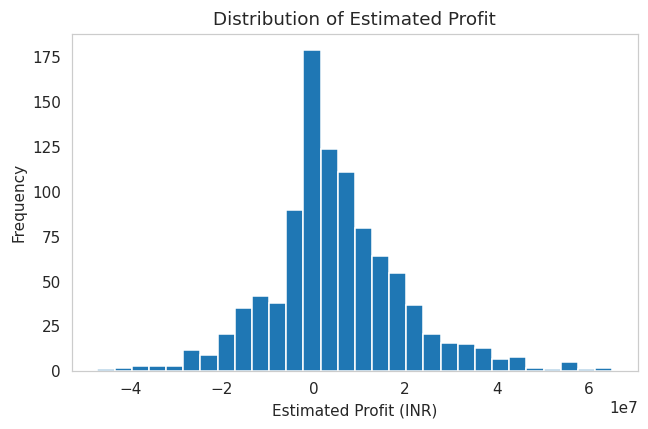

Mean profit: 4,955,421 | Median profit: 3,056,643


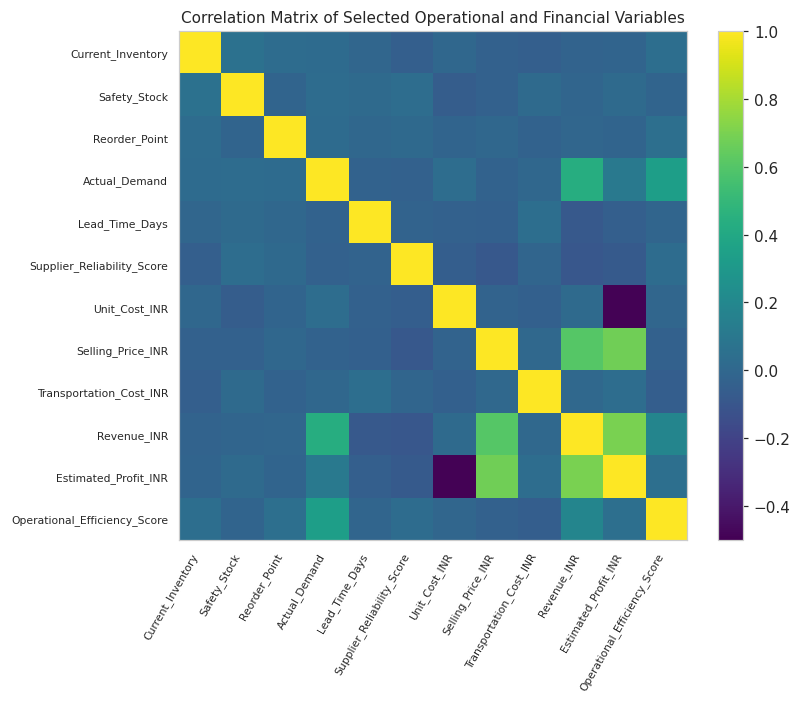

r(Transportation_Cost_INR, Total_Operational_Cost_INR) = 0.892
r(Forecast_Accuracy_Percent, Operational_Efficiency_Score) = 0.817
r(Revenue_INR, Estimated_Profit_INR) = 0.700
r(Selling_Price_INR, Estimated_Profit_INR) = 0.672
r(Unit_Cost_INR, Estimated_Profit_INR) = -0.494

5.1 LOGISTIC REGRESSION - ON-TIME DELIVERY
Accuracy : 0.904
ROC-AUC  : 0.97
              precision    recall  f1-score   support

        Late       0.93      0.94      0.93       181
     On-time       0.84      0.81      0.82        69

    accuracy                           0.90       250
   macro avg       0.88      0.88      0.88       250
weighted avg       0.90      0.90      0.90       250

Pseudo R-squared: 0.6356
LLR p-value     : 4.752749792406991e-113

Statsmodels p-values:
 const                         0.0000
Lead_Time_Days                0.0000
Supplier_Reliability_Score    0.0000
Delivery_Distance_KM          0.5504
Downtime_Hours                0.7672
Defect_Rate_Percent           0.7473
Order_Quan

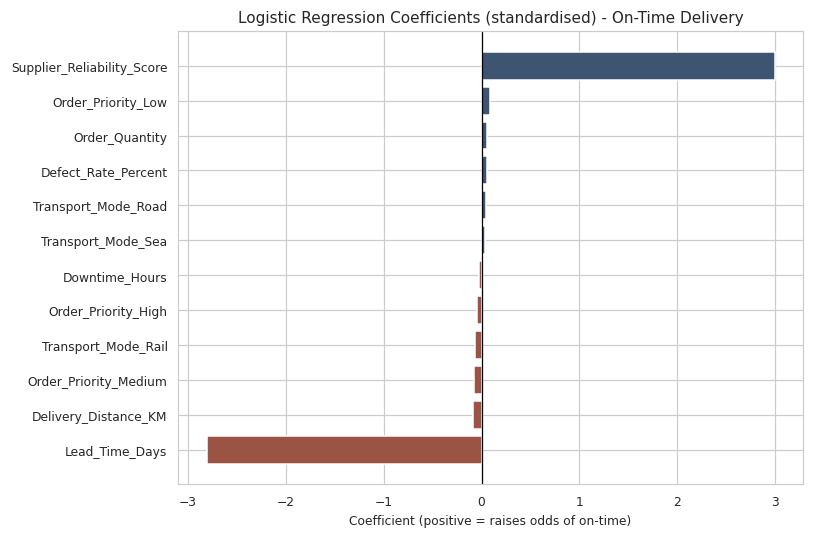

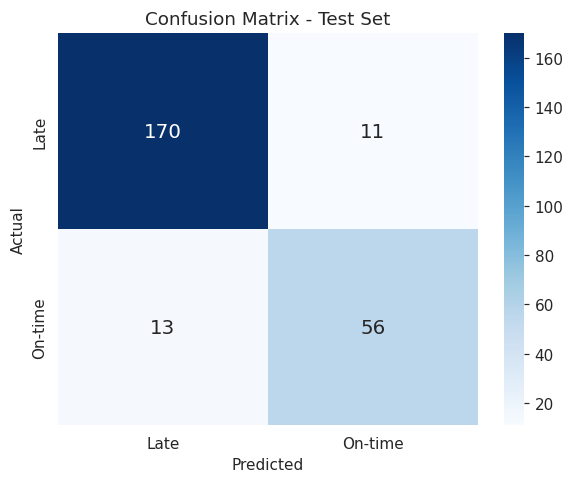

Correct classifications: 226 of 250


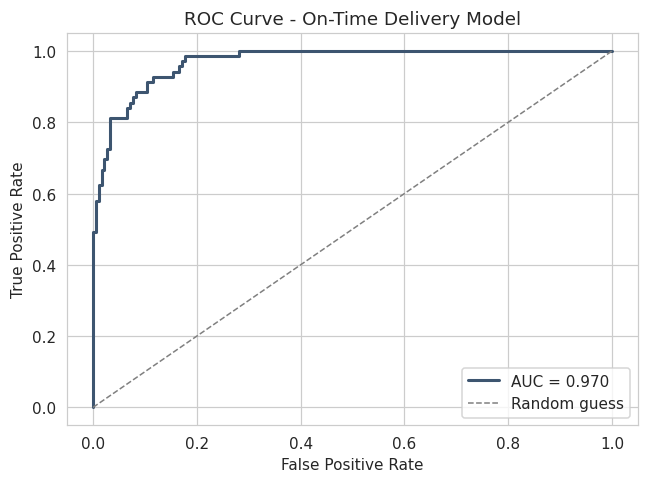

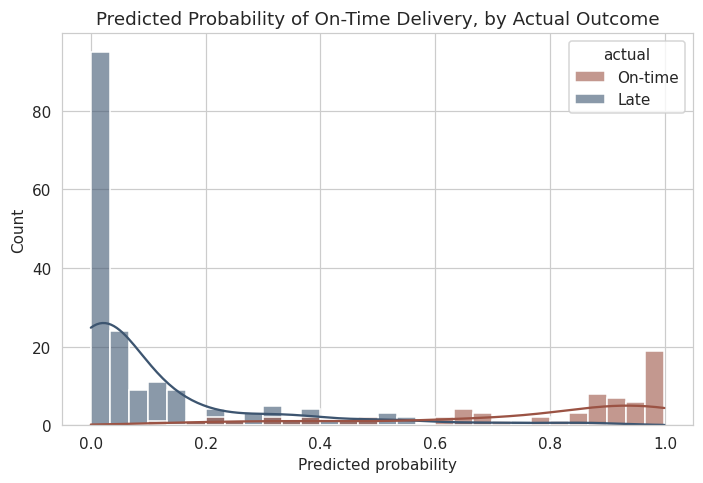

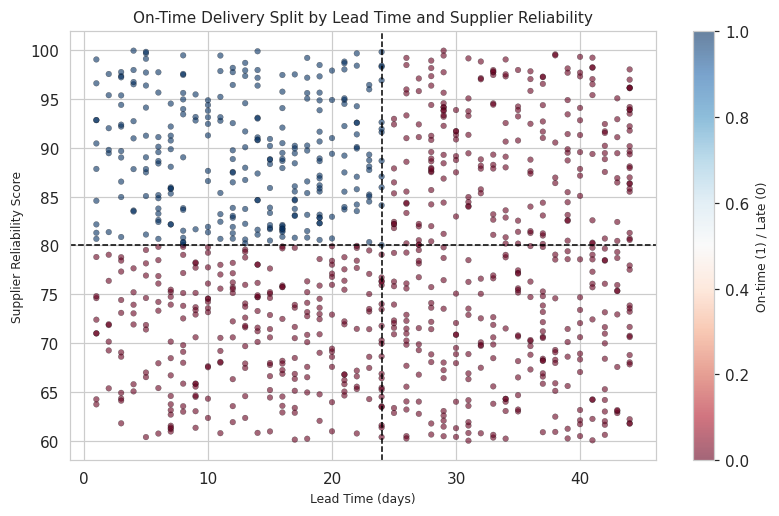


5.2 DECISION TREE - STOCKOUT RISK
Depth-3 tree  -> Acc: 0.844 | Macro-F1: 0.761 | Leaves: 8
Best params   : {'max_depth': 6, 'min_samples_leaf': 5}
Best CV macro-F1: 0.858
Tuned tree    -> Acc: 0.904 | Macro-F1: 0.831 | Leaves: 27
              precision    recall  f1-score   support

         Low       0.95      0.98      0.96       167
      Medium       0.71      0.75      0.73        20
        High       0.84      0.76      0.80        63

    accuracy                           0.90       250
   macro avg       0.83      0.83      0.83       250
weighted avg       0.90      0.90      0.90       250



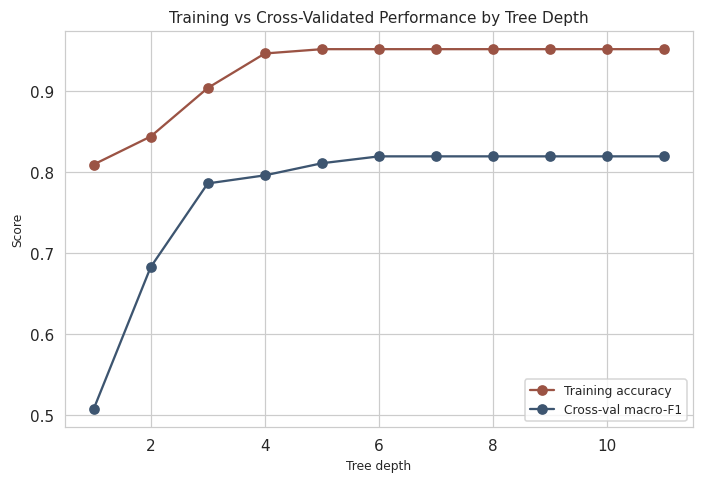

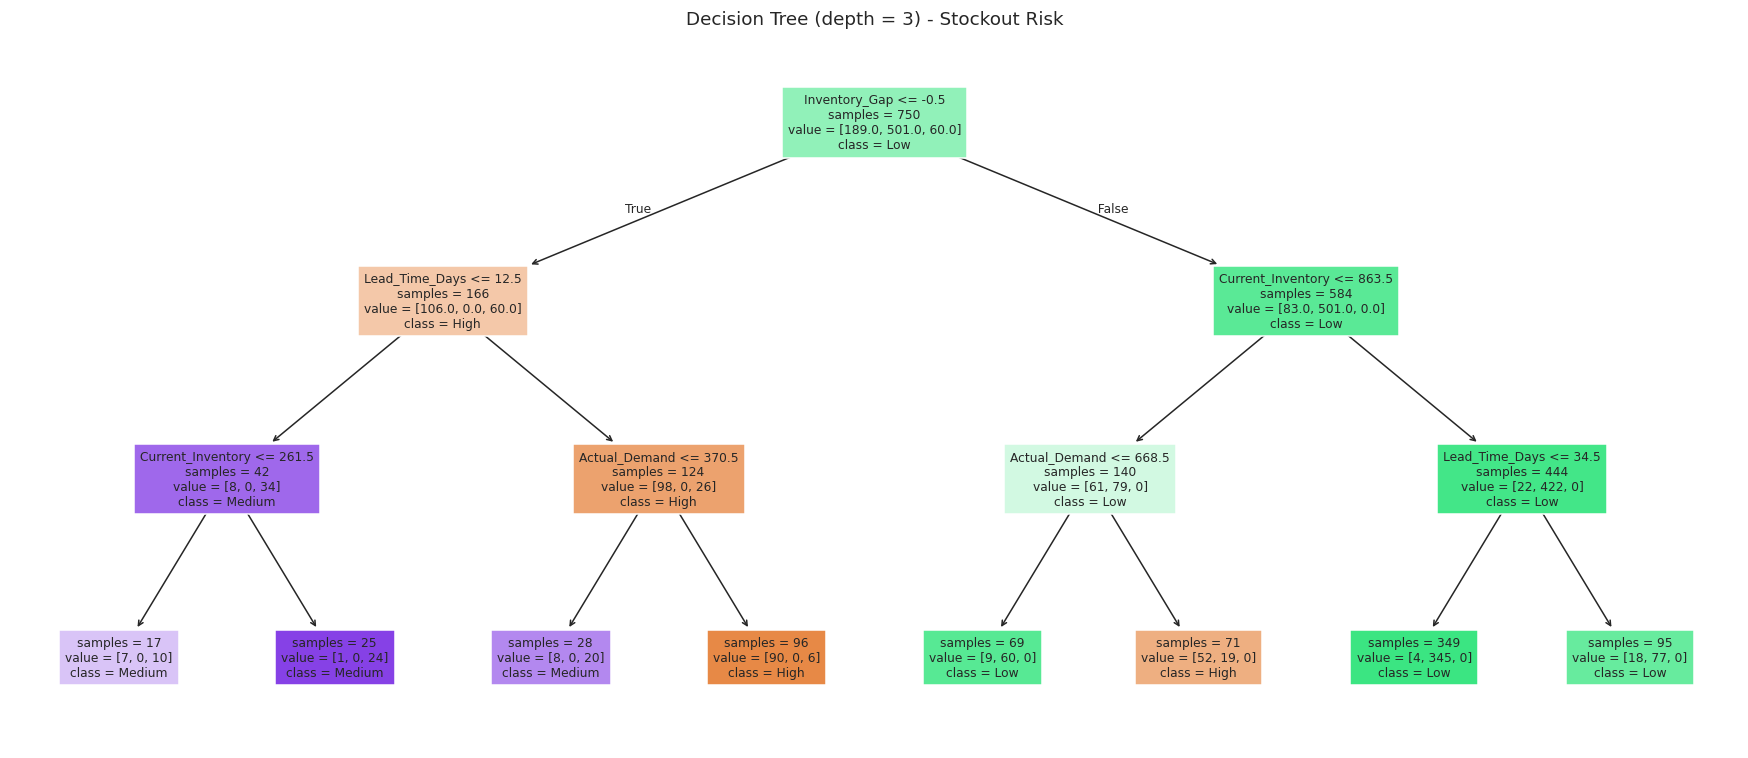

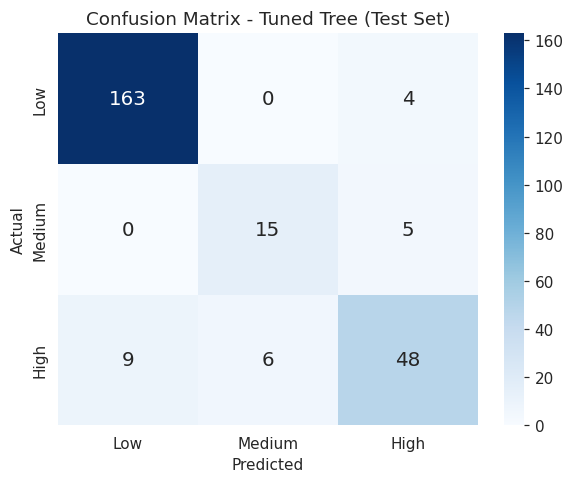


Tuned tree feature importance:
 Inventory_Gap        0.436
Actual_Demand        0.209
Current_Inventory    0.169
Lead_Time_Days       0.152
Safety_Gap           0.017
Order_Quantity       0.010
Forecast_Error       0.005
Reorder_Point        0.001


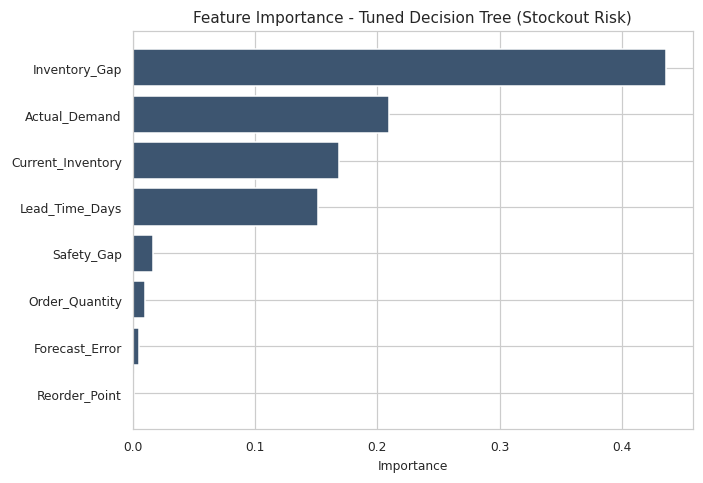

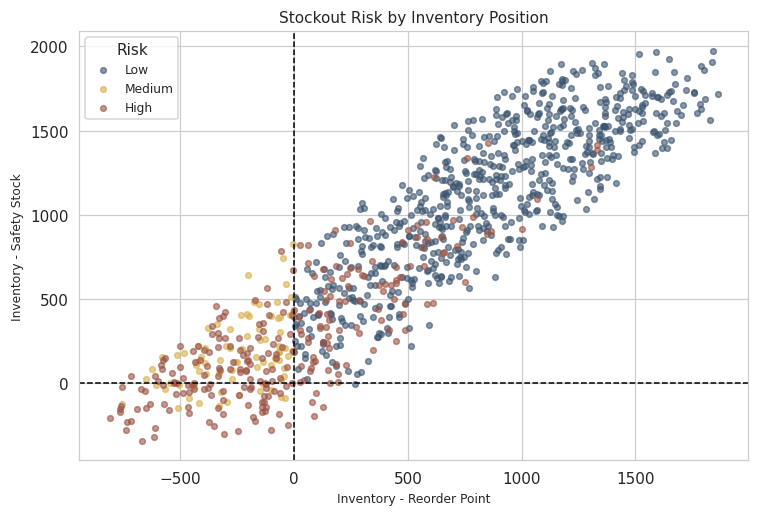


5.3 RANDOM FOREST - STOCKOUT RISK
Best RF params : {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV macro-F1: 0.887
RF -> Test Acc: 0.920 | Test Macro-F1: 0.874
              precision    recall  f1-score   support

         Low       0.93      0.99      0.96       167
      Medium       0.94      0.75      0.83        20
        High       0.89      0.78      0.83        63

    accuracy                           0.92       250
   macro avg       0.92      0.84      0.87       250
weighted avg       0.92      0.92      0.92       250


Single Tree  CV macro-F1: mean 0.858, std 0.049
Random Forest CV macro-F1: mean 0.887, std 0.029


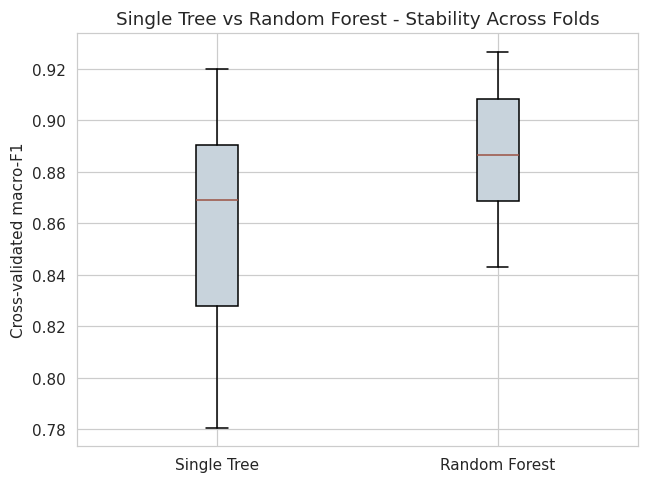

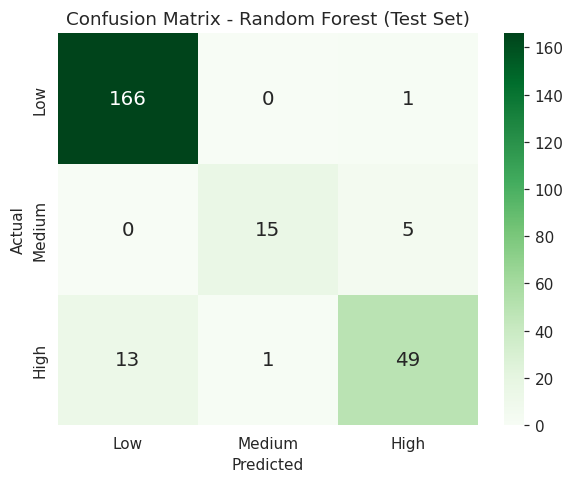

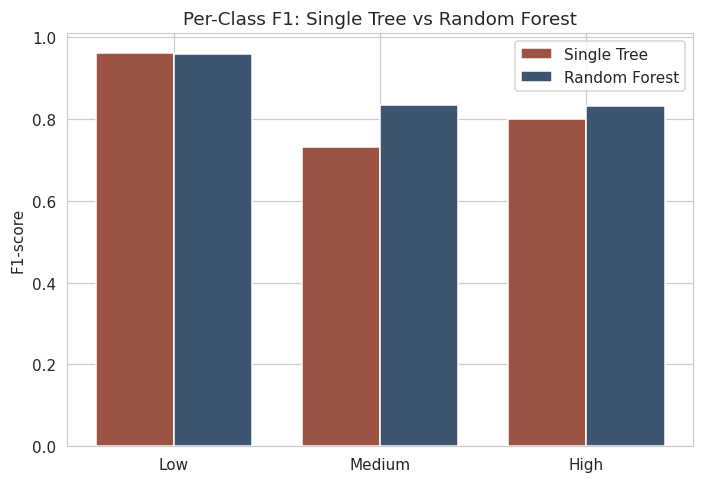

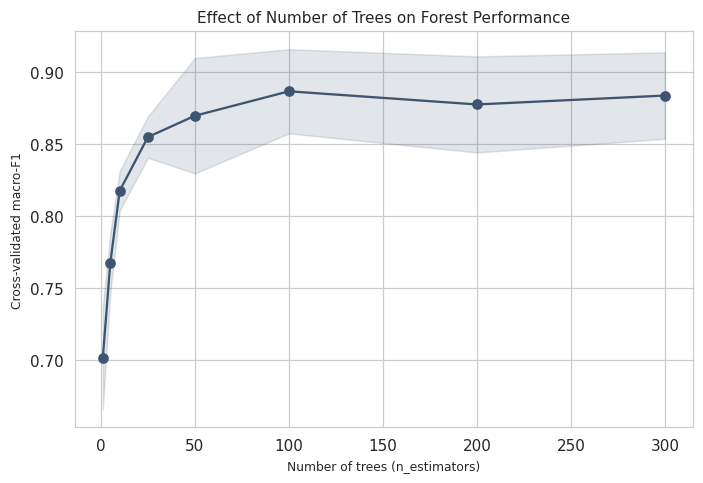


Random Forest feature importance:
 Inventory_Gap        0.218
Current_Inventory    0.187
Safety_Gap           0.167
Lead_Time_Days       0.106
Actual_Demand        0.098
Forecast_Error       0.054
Reorder_Point        0.030
Safety_Stock         0.029


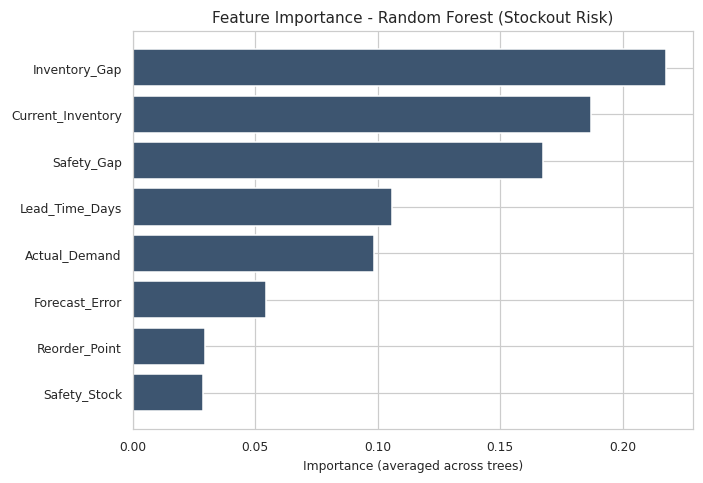


5.4 LINEAR REGRESSION - ESTIMATED PROFIT
R-squared: 0.672
RMSE     : INR 8,251,274
MAE      : INR 6,086,522

Top standardised coefficients (INR):
 Selling_Price_INR             9851702.0
Unit_Cost_INR                -7405164.0
Actual_Demand                 2173389.0
Order_Quantity                1381873.0
Supplier_Reliability_Score    -981826.0
Lead_Time_Days                -653571.0
Warehouse_Mumbai               623883.0
Transportation_Cost_INR        443563.0


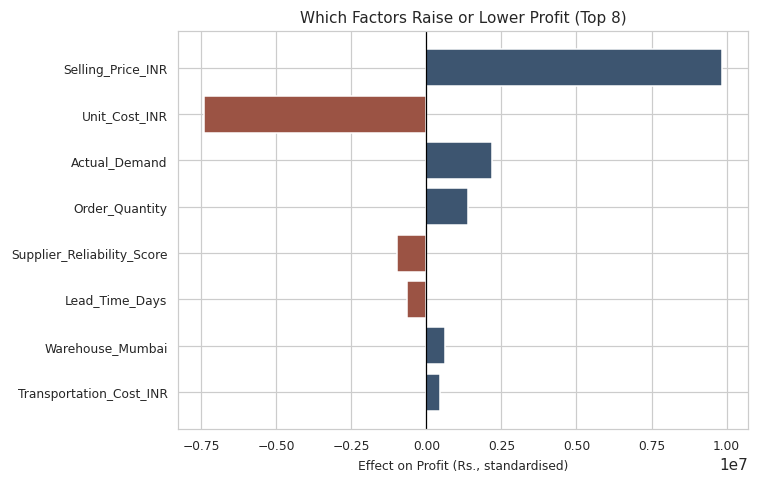

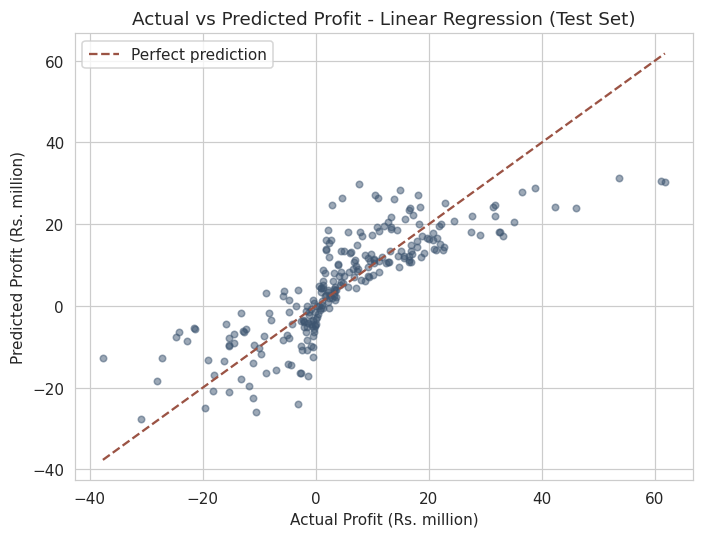


Done - all 21 figures and result tables generated.


In [1]:
# =============================================================================
# Advanced Analytics for Decision-Making - End Term Project
# Dataset: OPS_DS1.csv  (1,000 transactions x 38 fields)
# Reproduces every table / figure (Fig 1-21) in the final report.
# Run in Google Colab: paste into cells (or run as one cell) and upload OPS_DS1.csv
# =============================================================================

# ----------------------------- 0. SETUP --------------------------------------
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     StratifiedKFold, cross_val_score)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report,
                             r2_score, mean_squared_error, mean_absolute_error)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# Colour palette used in the report
BLUE, RED, GOLD = "#3D5570", "#9B5344", "#D9B04C"

# ----------------------------- 1. LOAD DATA ----------------------------------
# Option A (Colab): upload the file when prompted
try:
    from google.colab import files
    import os
    if not os.path.exists("OPS_DS1.csv"):
        print("Please upload OPS_DS1.csv ...")
        files.upload()
except ImportError:
    pass  # not running in Colab - expects OPS_DS1.csv in the working directory

# Option B (if you prefer the Excel file, comment the line below and use this):
# df = pd.read_excel("Supply_Chain_Efficiency_OPS_DS1.xlsx")
df = pd.read_csv("OPS_DS1.csv")

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nStockout_Risk (%):\n", (df["Stockout_Risk"].value_counts(normalize=True) * 100).round(1))
print("\nOn_Time_Delivery (%):\n", (df["On_Time_Delivery"].value_counts(normalize=True) * 100).round(1))

# ----------------------------- 2. DESCRIPTIVES -------------------------------
sel = ["Current_Inventory", "Reorder_Point", "Actual_Demand", "Lead_Time_Days",
       "Supplier_Reliability_Score", "Unit_Cost_INR", "Selling_Price_INR",
       "Delivery_Distance_KM", "Estimated_Profit_INR", "Operational_Efficiency_Score"]
desc = df[sel].agg(["mean", "std", "min", "median", "max"]).T
desc.columns = ["Mean", "Std. Dev.", "Min", "Median", "Max"]
print("\n=== Selected Descriptive Statistics ===")
print(desc.round(2).to_string(float_format=lambda x: f"{x:,.2f}"))

# Column-type split (27 numeric / 7 categorical / 3 IDs / 1 date)
id_cols = ["Transaction_ID", "Product_ID", "Supplier_ID"]
print("\nNumeric columns:", df.select_dtypes(include="number").shape[1])

# ----------------------------- 3. DATA PREPARATION ---------------------------
# Outlier screening (IQR rule)
num_cols_all = df.select_dtypes(include="number").columns
print("\n=== IQR outlier counts (top) ===")
out_counts = {}
for c in num_cols_all:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    out_counts[c] = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
print(pd.Series(out_counts).loc[lambda s: s > 0].sort_values(ascending=False).to_string())

# Capped copies (outliers retained in the raw columns)
df["Inventory_Turnover_Capped"] = df["Inventory_Turnover_Ratio"].clip(
    upper=df["Inventory_Turnover_Ratio"].quantile(0.95))
df["Downtime_Hours_Capped"] = df["Downtime_Hours"].clip(
    upper=df["Downtime_Hours"].quantile(0.99))

# Engineered features
df["Inventory_Gap"]   = df.Current_Inventory - df.Reorder_Point
df["Safety_Gap"]      = df.Current_Inventory - df.Safety_Stock
df["Forecast_Error"]  = df.Actual_Demand - df.Demand_Forecast

# ----------------------------- 4. EDA ----------------------------------------
print("\n=== Business checks ===")
print("Total cost = Holding+Ordering+Transport :",
      np.isclose(df.Total_Operational_Cost_INR,
                 df.Holding_Cost_INR + df.Ordering_Cost_INR + df.Transportation_Cost_INR, atol=0.05).mean())
print("Production actual > capacity           : {:.1%}".format((df.Production_Actual > df.Production_Capacity).mean()))
print("Selling price < unit cost              : {:.1%}  ({} rows)".format(
    (df.Selling_Price_INR < df.Unit_Cost_INR).mean(), int((df.Selling_Price_INR < df.Unit_Cost_INR).sum())))
print("Inventory < reorder point              : {:.1%}".format((df.Inventory_Gap < 0).mean()))
print("Inventory < safety stock               : {:.1%}".format((df.Safety_Gap < 0).mean()))
print("Forecast accuracy exactly 0            : {:.1%}".format((df.Forecast_Accuracy_Percent == 0).mean()))

# On-time rate by lead-time band and reliability
df["LT_band"] = pd.cut(df.Lead_Time_Days, [0, 6, 12, 18, 24, 30, 36, 44])
print("\nOn-time rate by lead-time band:\n",
      df.groupby("LT_band", observed=True).On_Time_Delivery.apply(lambda s: (s == "Yes").mean()).round(3))
print("\nOn-time rate by transport mode:\n",
      df.groupby("Transport_Mode").On_Time_Delivery.apply(lambda s: (s == "Yes").mean()).round(3))
rule = (df.Lead_Time_Days <= 24) & (df.Supplier_Reliability_Score > 80)
print("\nRule (LT<=24 & Reliability>80) accuracy on full data:",
      ((rule) == (df.On_Time_Delivery == "Yes")).mean(), "| on-time predicted:", int(rule.sum()))
print("\nStockout risk vs inventory position:\n",
      pd.crosstab(df.Inventory_Gap < 0, df.Stockout_Risk, normalize="index").round(2))

# --- Figure 1: Stockout risk distribution
fig, ax = plt.subplots(figsize=(6, 4))
df["Stockout_Risk"].value_counts().reindex(["Low", "Medium", "High"]).plot(kind="bar", color="#1f77b4", ax=ax)
ax.set_title("Stockout Risk Distribution"); ax.set_xlabel("Stockout Risk")
ax.set_ylabel("Number of Transactions"); plt.xticks(rotation=0); ax.grid(False)
plt.tight_layout(); plt.show()

# --- Figure 2: On-time delivery distribution
fig, ax = plt.subplots(figsize=(6, 4))
df["On_Time_Delivery"].value_counts().reindex(["No", "Yes"]).plot(kind="bar", color="#1f77b4", ax=ax)
ax.set_title("On-Time Delivery Distribution"); ax.set_xlabel("On-Time Delivery")
ax.set_ylabel("Number of Transactions"); plt.xticks(rotation=0); ax.grid(False)
plt.tight_layout(); plt.show()

# --- Figure 3: Profit distribution
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df.Estimated_Profit_INR, bins=30, color="#1f77b4")
ax.set_title("Distribution of Estimated Profit"); ax.set_xlabel("Estimated Profit (INR)")
ax.set_ylabel("Frequency"); ax.grid(False)
plt.tight_layout(); plt.show()
print("Mean profit: {:,.0f} | Median profit: {:,.0f}".format(
    df.Estimated_Profit_INR.mean(), df.Estimated_Profit_INR.median()))

# --- Figure 4: Correlation matrix
corr_cols = ["Current_Inventory", "Safety_Stock", "Reorder_Point", "Actual_Demand",
             "Lead_Time_Days", "Supplier_Reliability_Score", "Unit_Cost_INR",
             "Selling_Price_INR", "Transportation_Cost_INR", "Revenue_INR",
             "Estimated_Profit_INR", "Operational_Efficiency_Score"]
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="viridis", vmin=-0.5, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=60, ha="right", fontsize=7)
ax.set_yticklabels(corr_cols, fontsize=7)
ax.set_title("Correlation Matrix of Selected Operational and Financial Variables", fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.046); ax.grid(False)
plt.tight_layout(); plt.show()
# Extra correlations quoted in the report
full_corr = df[list(set(corr_cols + ["Total_Operational_Cost_INR", "Forecast_Accuracy_Percent"]))].corr()
for a, b in [("Transportation_Cost_INR", "Total_Operational_Cost_INR"),
             ("Forecast_Accuracy_Percent", "Operational_Efficiency_Score"),
             ("Revenue_INR", "Estimated_Profit_INR"),
             ("Selling_Price_INR", "Estimated_Profit_INR"),
             ("Unit_Cost_INR", "Estimated_Profit_INR")]:
    print(f"r({a}, {b}) = {full_corr.loc[a, b]:.3f}")

# =============================================================================
# 5.1  LOGISTIC REGRESSION - ON-TIME DELIVERY
# =============================================================================
print("\n" + "=" * 70 + "\n5.1 LOGISTIC REGRESSION - ON-TIME DELIVERY\n" + "=" * 70)

num_feats = ["Lead_Time_Days", "Supplier_Reliability_Score", "Delivery_Distance_KM",
             "Downtime_Hours", "Defect_Rate_Percent", "Order_Quantity"]
cat_feats = ["Transport_Mode", "Order_Priority"]

X = pd.concat([df[num_feats], pd.get_dummies(df[cat_feats], drop_first=True)], axis=1).astype(float)
y = (df.On_Time_Delivery == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

clf = LogisticRegression(max_iter=2000)
clf.fit(X_train_s, y_train)

y_pred = clf.predict(X_test_s)
y_prob = clf.predict_proba(X_test_s)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))
print(classification_report(y_test, y_pred, target_names=["Late", "On-time"], digits=2))

# statsmodels version for Pseudo R2, LLR p-value, p-values and odds ratios
try:
    X_sm = pd.DataFrame(X_train_s, columns=X.columns, index=X_train.index)   # keep index aligned with y_train
    sm_logit = sm.Logit(y_train, sm.add_constant(X_sm)).fit(disp=0, maxiter=200)
    print("Pseudo R-squared:", round(sm_logit.prsquared, 4))
    print("LLR p-value     :", sm_logit.llr_pvalue)
    print("\nStatsmodels p-values:\n", sm_logit.pvalues.round(4).to_string())
except Exception as e:  # perfect / quasi-separation can raise errors
    print("statsmodels Logit issue (quasi-separation):", e)

coef = pd.DataFrame({"Feature": X.columns, "Coef": clf.coef_[0],
                     "Odds_Ratio": np.exp(clf.coef_[0])}).sort_values("Coef")
print("\nStandardised coefficients / odds ratios:\n", coef.round(3).to_string(index=False))

# --- Figure 5: Coefficients
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(coef.Feature, coef.Coef, color=[BLUE if c > 0 else RED for c in coef.Coef])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Logistic Regression Coefficients (standardised) - On-Time Delivery", fontsize=10)
ax.set_xlabel("Coefficient (positive = raises odds of on-time)", fontsize=8)
ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

# --- Figure 6: Confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Late", "On-time"],
            yticklabels=["Late", "On-time"], annot_kws={"size": 13}, ax=ax)
ax.set_title("Confusion Matrix - Test Set"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()
print("Correct classifications:", cm.trace(), "of", cm.sum())

# --- Figure 7: ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(fpr, tpr, color=BLUE, lw=2, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="Random guess")
ax.set_title("ROC Curve - On-Time Delivery Model")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

# --- Figure 8: Predicted probability distribution
prob_df = pd.DataFrame({"prob": y_prob,
                        "actual": np.where(y_test.values == 1, "On-time", "Late")})
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.histplot(data=prob_df, x="prob", hue="actual", bins=30, kde=True,
             palette={"On-time": RED, "Late": BLUE}, alpha=0.6, ax=ax)
ax.set_title("Predicted Probability of On-Time Delivery, by Actual Outcome")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Count")
plt.tight_layout(); plt.show()

# --- Figure 9: Lead time vs reliability scatter
fig, ax = plt.subplots(figsize=(7.5, 4.8))
sc = ax.scatter(df.Lead_Time_Days, df.Supplier_Reliability_Score,
                c=(df.On_Time_Delivery == "Yes").astype(int), cmap="RdBu",
                s=14, alpha=0.6, edgecolor="k", linewidth=0.2)
ax.axvline(24, color="black", ls="--", lw=1); ax.axhline(80, color="black", ls="--", lw=1)
ax.set_title("On-Time Delivery Split by Lead Time and Supplier Reliability", fontsize=10)
ax.set_xlabel("Lead Time (days)", fontsize=8); ax.set_ylabel("Supplier Reliability Score", fontsize=8)
cb = plt.colorbar(sc, ax=ax); cb.set_label("On-time (1) / Late (0)", fontsize=8)
plt.tight_layout(); plt.show()

# =============================================================================
# 5.2  DECISION TREE - STOCKOUT RISK
# =============================================================================
print("\n" + "=" * 70 + "\n5.2 DECISION TREE - STOCKOUT RISK\n" + "=" * 70)

num_feats = ["Current_Inventory", "Safety_Stock", "Reorder_Point", "Inventory_Gap",
             "Safety_Gap", "Actual_Demand", "Demand_Forecast", "Forecast_Error",
             "Lead_Time_Days", "Supplier_Reliability_Score", "Order_Quantity"]
cat_feats = ["Product_Category", "Warehouse"]

X = pd.concat([df[num_feats], pd.get_dummies(df[cat_feats], drop_first=True)], axis=1).astype(float)
y = df.Stockout_Risk
classes = ["Low", "Medium", "High"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

# ---- Depth-3 interpretable tree
dt3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42).fit(X_train, y_train)
p3 = dt3.predict(X_test)
print("Depth-3 tree  -> Acc: {:.3f} | Macro-F1: {:.3f} | Leaves: {}".format(
    accuracy_score(y_test, p3), f1_score(y_test, p3, average="macro"), dt3.get_n_leaves()))

# ---- Grid search for tuned tree
param_grid = {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [5, 10, 20]}
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring="f1_macro")
grid_dt.fit(X_train, y_train)
dt = grid_dt.best_estimator_
p_dt = dt.predict(X_test)
print("Best params   :", grid_dt.best_params_)
print("Best CV macro-F1: {:.3f}".format(grid_dt.best_score_))
print("Tuned tree    -> Acc: {:.3f} | Macro-F1: {:.3f} | Leaves: {}".format(
    accuracy_score(y_test, p_dt), f1_score(y_test, p_dt, average="macro"), dt.get_n_leaves()))
print(classification_report(y_test, p_dt, labels=classes, digits=2))

# --- Figure 10: Train vs CV performance by depth
depths = range(1, 12)
train_acc, cv_f1 = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=10, random_state=42)
    m.fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    cv_f1.append(cross_val_score(m, X_train, y_train, cv=5, scoring="f1_macro").mean())
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(depths, train_acc, "o-", color=RED, label="Training accuracy")
ax.plot(depths, cv_f1, "o-", color=BLUE, label="Cross-val macro-F1")
ax.set_title("Training vs Cross-Validated Performance by Tree Depth", fontsize=10)
ax.set_xlabel("Tree depth", fontsize=8); ax.set_ylabel("Score", fontsize=8); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# --- Figure 11: Depth-3 tree structure
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(dt3, feature_names=X.columns, class_names=dt3.classes_, filled=True,
          impurity=False, fontsize=8, ax=ax)
ax.set_title("Decision Tree (depth = 3) - Stockout Risk")
plt.tight_layout(); plt.show()

# --- Figure 12: Confusion matrix - tuned tree
cm = confusion_matrix(y_test, p_dt, labels=classes)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes,
            yticklabels=classes, annot_kws={"size": 13}, ax=ax)
ax.set_title("Confusion Matrix - Tuned Tree (Test Set)"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

# --- Figure 13: Feature importance - tuned tree
imp_dt = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTuned tree feature importance:\n", imp_dt.head(8).round(3).to_string())
top = imp_dt.head(8)[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(top.index, top.values, color=BLUE)
ax.set_title("Feature Importance - Tuned Decision Tree (Stockout Risk)", fontsize=10)
ax.set_xlabel("Importance", fontsize=8); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

# --- Figure 14: Stockout risk by inventory position
fig, ax = plt.subplots(figsize=(7, 4.8))
for cls, col in zip(classes, [BLUE, GOLD, RED]):
    s = df[df.Stockout_Risk == cls]
    ax.scatter(s.Inventory_Gap, s.Safety_Gap, s=14, alpha=0.6, color=col, label=cls)
ax.axvline(0, color="black", ls="--", lw=1); ax.axhline(0, color="black", ls="--", lw=1)
ax.set_title("Stockout Risk by Inventory Position", fontsize=10)
ax.set_xlabel("Inventory - Reorder Point", fontsize=8); ax.set_ylabel("Inventory - Safety Stock", fontsize=8)
ax.legend(title="Risk", fontsize=8)
plt.tight_layout(); plt.show()

# =============================================================================
# 5.3  RANDOM FOREST - STOCKOUT RISK
# =============================================================================
print("\n" + "=" * 70 + "\n5.3 RANDOM FOREST - STOCKOUT RISK\n" + "=" * 70)

param_grid_rf = {"n_estimators": [100, 300], "max_depth": [6, 10, None], "min_samples_leaf": [1, 5]}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf,
                       cv=5, scoring="f1_macro", n_jobs=-1)
grid_rf.fit(X_train, y_train)
rf = grid_rf.best_estimator_
p_rf = rf.predict(X_test)
print("Best RF params :", grid_rf.best_params_)
print("Best CV macro-F1: {:.3f}".format(grid_rf.best_score_))
print("RF -> Test Acc: {:.3f} | Test Macro-F1: {:.3f}".format(
    accuracy_score(y_test, p_rf), f1_score(y_test, p_rf, average="macro")))
print(classification_report(y_test, p_rf, labels=classes, digits=2))

# --- Cross-validation stability (same folds for both models)
skf = StratifiedKFold(n_splits=5)   # same folds GridSearchCV(cv=5) uses
cv_tree = cross_val_score(dt, X_train, y_train, cv=skf, scoring="f1_macro")
cv_rf = cross_val_score(rf, X_train, y_train, cv=skf, scoring="f1_macro")
print("\nSingle Tree  CV macro-F1: mean {:.3f}, std {:.3f}".format(cv_tree.mean(), cv_tree.std()))
print("Random Forest CV macro-F1: mean {:.3f}, std {:.3f}".format(cv_rf.mean(), cv_rf.std()))

# --- Figure 15: CV stability boxplot
fig, ax = plt.subplots(figsize=(6, 4.5))
bp = ax.boxplot([cv_tree, cv_rf], patch_artist=True, medianprops=dict(color=RED))
ax.set_xticklabels(["Single Tree", "Random Forest"])
for patch in bp["boxes"]:
    patch.set_facecolor("#C8D3DC")
ax.set_title("Single Tree vs Random Forest - Stability Across Folds")
ax.set_ylabel("Cross-validated macro-F1")
plt.tight_layout(); plt.show()

# --- Figure 16: Confusion matrix - RF
cm = confusion_matrix(y_test, p_rf, labels=classes)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=classes,
            yticklabels=classes, annot_kws={"size": 13}, ax=ax)
ax.set_title("Confusion Matrix - Random Forest (Test Set)"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

# --- Figure 17: Per-class F1 comparison
f1_dt = f1_score(y_test, p_dt, labels=classes, average=None)
f1_rf = f1_score(y_test, p_rf, labels=classes, average=None)
xpos = np.arange(3); w = 0.38
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(xpos - w / 2, f1_dt, w, color=RED, label="Single Tree")
ax.bar(xpos + w / 2, f1_rf, w, color=BLUE, label="Random Forest")
ax.set_xticks(xpos); ax.set_xticklabels(classes)
ax.set_title("Per-Class F1: Single Tree vs Random Forest"); ax.set_ylabel("F1-score"); ax.legend()
plt.tight_layout(); plt.show()

# --- Figure 18: Effect of number of trees
n_list = [1, 5, 10, 25, 50, 100, 200, 300]
means, stds = [], []
for n in n_list:
    m = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    sc_ = cross_val_score(m, X_train, y_train, cv=skf, scoring="f1_macro")
    means.append(sc_.mean()); stds.append(sc_.std())
means, stds = np.array(means), np.array(stds)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(n_list, means, "o-", color=BLUE)
ax.fill_between(n_list, means - stds, means + stds, color=BLUE, alpha=0.15)
ax.set_title("Effect of Number of Trees on Forest Performance", fontsize=10)
ax.set_xlabel("Number of trees (n_estimators)", fontsize=8); ax.set_ylabel("Cross-validated macro-F1", fontsize=8)
plt.tight_layout(); plt.show()

# --- Figure 19: RF feature importance
imp_rf = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nRandom Forest feature importance:\n", imp_rf.head(8).round(3).to_string())
top = imp_rf.head(8)[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(top.index, top.values, color=BLUE)
ax.set_title("Feature Importance - Random Forest (Stockout Risk)", fontsize=10)
ax.set_xlabel("Importance (averaged across trees)", fontsize=8); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

# =============================================================================
# 5.4  LINEAR REGRESSION - PROFIT
# =============================================================================
print("\n" + "=" * 70 + "\n5.4 LINEAR REGRESSION - ESTIMATED PROFIT\n" + "=" * 70)

num_feats = ["Order_Quantity", "Actual_Demand", "Selling_Price_INR", "Unit_Cost_INR",
             "Lead_Time_Days", "Delivery_Distance_KM", "Transportation_Cost_INR",
             "Supplier_Reliability_Score", "Defect_Rate_Percent", "Machine_Utilization_Percent"]
cat_feats = ["Product_Category", "Warehouse", "Order_Priority"]

X = pd.concat([df[num_feats], pd.get_dummies(df[cat_feats], drop_first=True)], axis=1).astype(float)
y = df.Estimated_Profit_INR

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LinearRegression().fit(X_train_s, y_train)
pred = model.predict(X_test_s)

print("R-squared: {:.3f}".format(r2_score(y_test, pred)))
print("RMSE     : INR {:,.0f}".format(np.sqrt(mean_squared_error(y_test, pred))))
print("MAE      : INR {:,.0f}".format(mean_absolute_error(y_test, pred)))

coefs = pd.Series(model.coef_, index=X.columns)
print("\nTop standardised coefficients (INR):\n",
      coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8).round(0).to_string())

# --- Figure 20: Top factors
top8 = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top8.index, top8.values, color=[BLUE if v > 0 else RED for v in top8.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Which Factors Raise or Lower Profit (Top 8)", fontsize=10)
ax.set_xlabel("Effect on Profit (Rs., standardised)", fontsize=8); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

# --- Figure 21: Actual vs predicted
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(y_test / 1e6, pred / 1e6, s=18, alpha=0.5, color=BLUE)
lims = [min(y_test.min(), pred.min()) / 1e6, max(y_test.max(), pred.max()) / 1e6]
ax.plot(lims, lims, "--", color=RED, label="Perfect prediction")
ax.set_title("Actual vs Predicted Profit - Linear Regression (Test Set)")
ax.set_xlabel("Actual Profit (Rs. million)"); ax.set_ylabel("Predicted Profit (Rs. million)"); ax.legend()
plt.tight_layout(); plt.show()

print("\nDone - all 21 figures and result tables generated.")